# Permission-Aware Vector Search: results

This notebook only **reads** the result files written by the pipeline (`results/`). It does not run any
experiment itself, so it is fast and gives the same output every time.

| Experiment | Script | Result files |
|---|---|---|
| Recall and latency vs. permission selectivity | `src/pavs/bench.py` | `bench_<tag>.csv` |
| Leakage test suite (every role, both methods) | `tests/test_leakage.py` | `leak_tests_junit.xml` |
| Revocation leak window (Kafka -> Spark -> Milvus) | `src/pavs/revocation_bench.py` | `revocation_<tag>.csv` |
| Where the leak window comes from | `src/pavs/revocation_breakdown.py` | `revocation_breakdown_<tag>.csv` |

Tags: `demo100k` = 100,000 arXiv abstracts, `corpus1m` = 1,000,000 arXiv abstracts.

In [1]:
import glob, os
import pandas as pd
import xml.etree.ElementTree as ET
from IPython.display import Image, display, Markdown

R = os.environ.get("PAVS_RESULTS", "/app/results")
pd.options.display.float_format = "{:.3f}".format
print(sorted(os.path.basename(p) for p in glob.glob(f"{R}/*")))

['bench_corpus1m.csv', 'bench_corpus1m_faiss.csv', 'bench_corpus1m_milvus.csv', 'bench_demo100k.csv', 'latency_vs_selectivity_corpus1m.png', 'latency_vs_selectivity_corpus1m_faiss.png', 'latency_vs_selectivity_corpus1m_milvus.png', 'latency_vs_selectivity_demo100k.png', 'leak_tests_junit.xml', 'leak_tests_junit_1m.xml', 'mutation_check_junit.xml', 'recall_vs_selectivity_corpus1m.png', 'recall_vs_selectivity_corpus1m_faiss.png', 'recall_vs_selectivity_corpus1m_milvus.png', 'recall_vs_selectivity_demo100k.png', 'revocation_breakdown_demo100k.csv', 'revocation_breakdown_demo100k_split.csv', 'revocation_breakdown_demo100k_tuned.csv', 'revocation_comparison.png', 'revocation_demo100k.csv', 'revocation_demo100k_split.csv', 'revocation_demo100k_tuned.csv', 'revocation_window_demo100k.png', 'revocation_window_demo100k_split.png', 'revocation_window_demo100k_tuned.png']


## 1. Recall@10 vs. selectivity

*Selectivity* = share of all documents the user is allowed to see. Recall@10 is measured against an exact
(brute force) search over only the allowed documents, so 1.0 means "found the true 10 best allowed documents".

In [2]:
ORDER = ["milvus_filter", "milvus_partition", "faiss_prefilter", "faiss_post_10x", "faiss_postfilter"]
benches = {os.path.basename(p)[6:-4]: pd.read_csv(p) for p in sorted(glob.glob(f"{R}/bench_*.csv"))}
for tag, df in benches.items():
    display(Markdown(f"**{tag}**: {int(df.n_docs.iloc[0]):,} documents, {int(df.queries.iloc[0])} queries, k={int(df.k.iloc[0])}, HNSW ef={int(df.ef.iloc[0])}"))
    t = df.pivot_table(index="method", columns="target", values="recall_mean").reindex([m for m in ORDER if m in set(df.method)])
    t = t[sorted(t.columns, reverse=True)]
    t.columns = [f"{v:.1%}" for v in t.columns]
    display(t)

**corpus1m**: 1,000,000 documents, 500 queries, k=10, HNSW ef=64

,100.0%,50.0%,20.0%,5.0%,1.0%,0.1%
method,,,,,,
milvus_filter,0.971,0.957,0.975,1.000,1.000,1.000
milvus_partition,0.974,0.957,0.960,0.976,0.994,1.000
faiss_prefilter,0.947,0.933,0.724,0.583,0.443,0.094
faiss_post_10x,0.963,0.954,0.594,0.445,0.103,0.010
faiss_postfilter,0.947,0.497,0.194,0.049,0.013,0.002


**corpus1m_faiss**: 1,000,000 documents, 500 queries, k=10, HNSW ef=64

,100.0%,50.0%,20.0%,5.0%,1.0%,0.1%
method,,,,,,
faiss_prefilter,0.947,0.933,0.724,0.583,0.443,0.094
faiss_post_10x,0.963,0.954,0.594,0.445,0.103,0.010
faiss_postfilter,0.947,0.497,0.194,0.049,0.013,0.002


**corpus1m_milvus**: 1,000,000 documents, 500 queries, k=10, HNSW ef=64

,100.0%,50.0%,20.0%,5.0%,1.0%,0.1%
method,,,,,,
milvus_filter,0.971,0.957,0.975,1.000,1.000,1.000
milvus_partition,0.974,0.957,0.960,0.976,0.994,1.000


**demo100k**: 100,000 documents, 500 queries, k=10, HNSW ef=64

,100.0%,50.0%,20.0%,5.0%,1.0%,0.1%
method,,,,,,
milvus_filter,0.978,0.971,0.979,1.000,1.000,1.000
milvus_partition,0.991,0.977,0.975,0.998,1.000,1.000
faiss_prefilter,0.969,0.955,0.748,0.690,0.476,0.071
faiss_post_10x,0.982,0.973,0.633,0.464,0.103,0.008
faiss_postfilter,0.969,0.489,0.193,0.048,0.009,0.001


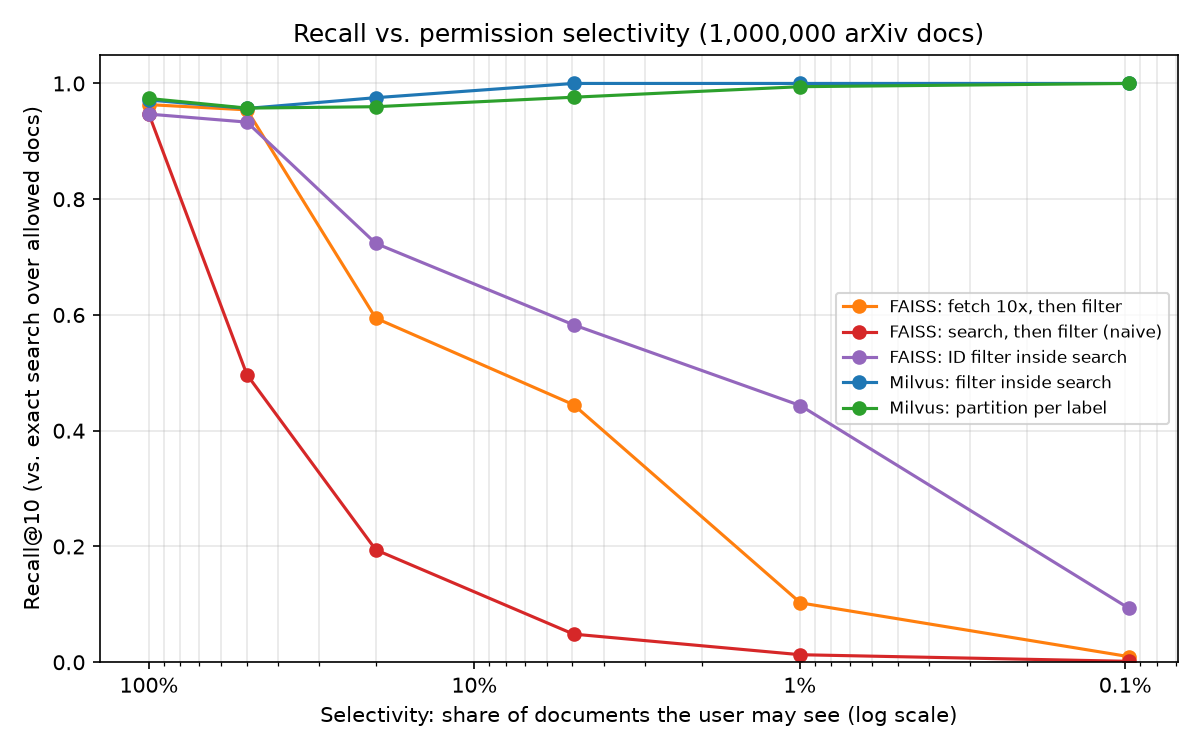

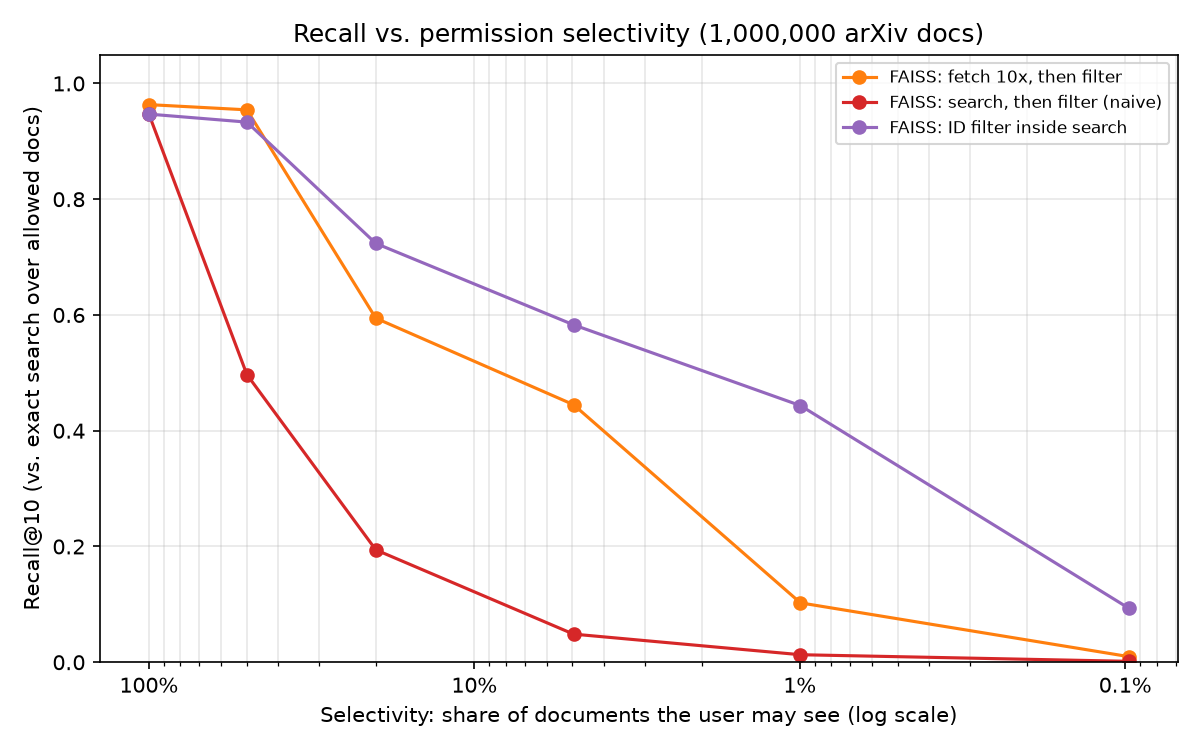

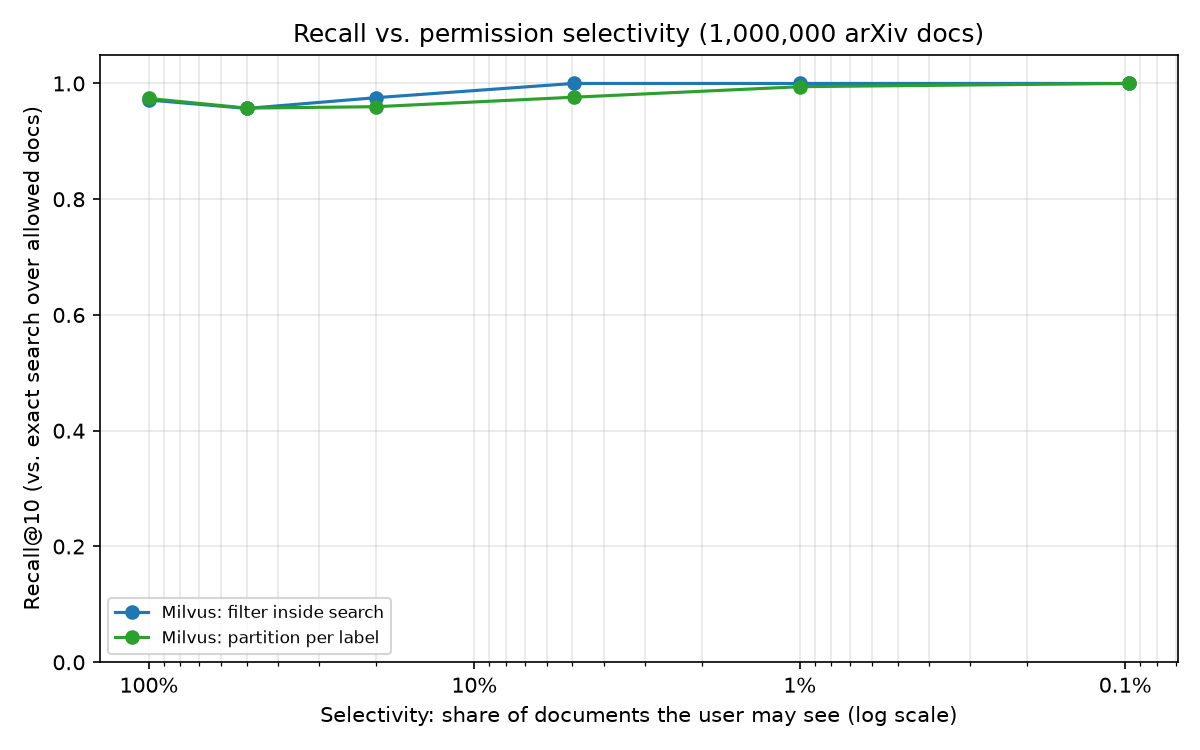

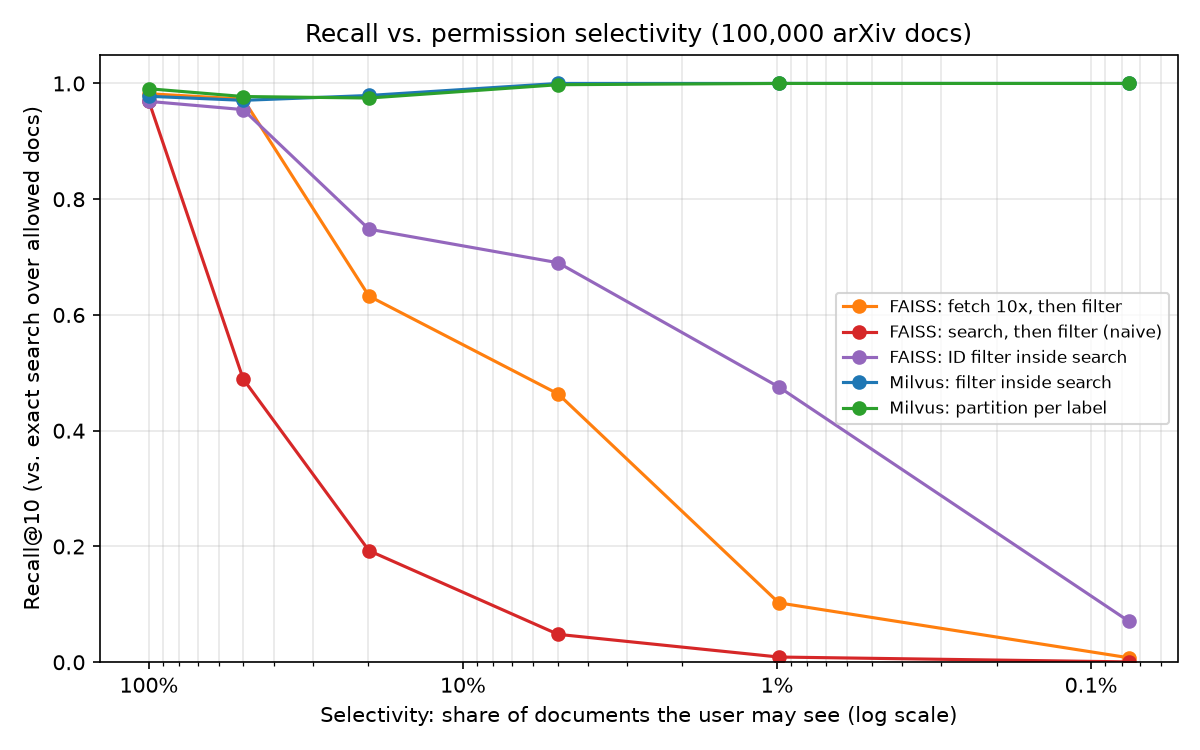

In [3]:
for tag in benches:
    p = f"{R}/recall_vs_selectivity_{tag}.png"
    if os.path.exists(p):
        display(Image(p, width=700))

## 2. Latency (p95, milliseconds) vs. selectivity

Caveat: FAISS runs inside the benchmark process; Milvus is a separate server reached over gRPC, so every
Milvus number includes a network round trip and request parsing (about 2-3 ms on this laptop).

**corpus1m**

,100.0%,50.0%,20.0%,5.0%,1.0%,0.1%
method,,,,,,
milvus_filter,19.600,6.610,10.220,14.290,8.750,5.090
milvus_partition,8.410,4.620,5.080,4.560,4.490,4.120
faiss_prefilter,0.980,1.340,0.680,0.700,0.780,0.710
faiss_post_10x,1.420,1.100,1.010,0.980,0.900,0.930
faiss_postfilter,0.700,0.670,0.750,0.650,0.740,0.720


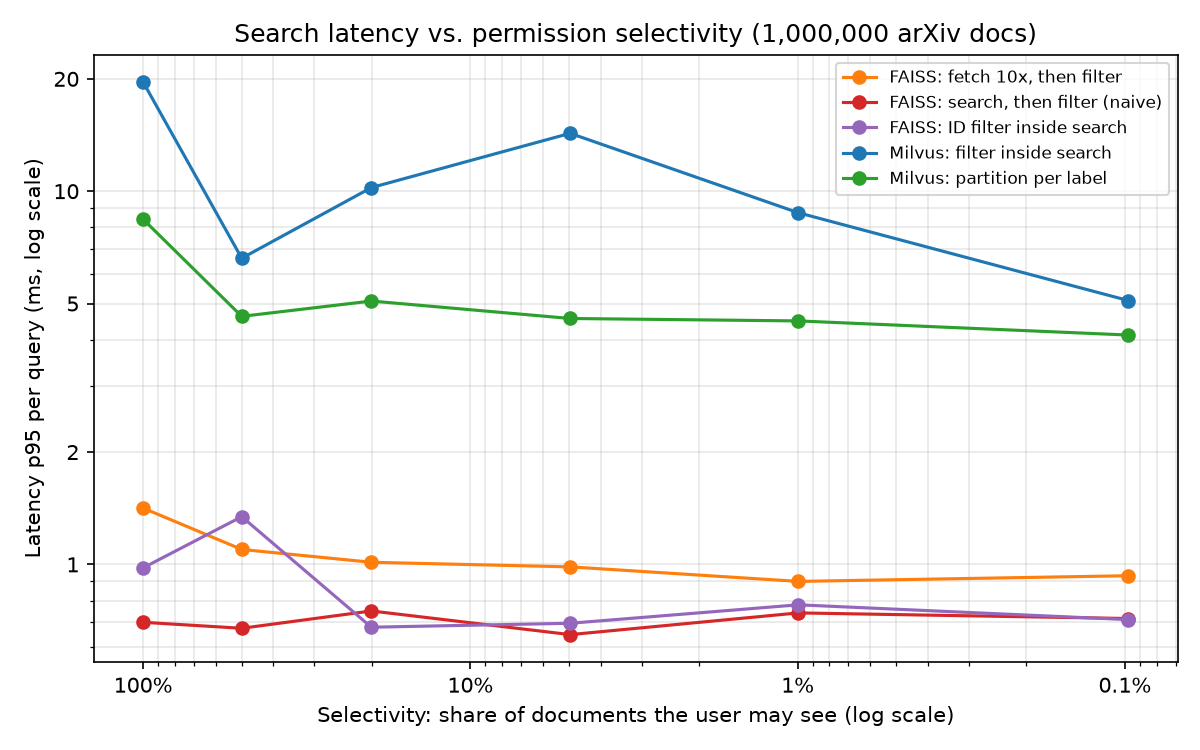

**corpus1m_faiss**

,100.0%,50.0%,20.0%,5.0%,1.0%,0.1%
method,,,,,,
faiss_prefilter,0.980,1.340,0.680,0.700,0.780,0.710
faiss_post_10x,1.420,1.100,1.010,0.980,0.900,0.930
faiss_postfilter,0.700,0.670,0.750,0.650,0.740,0.720


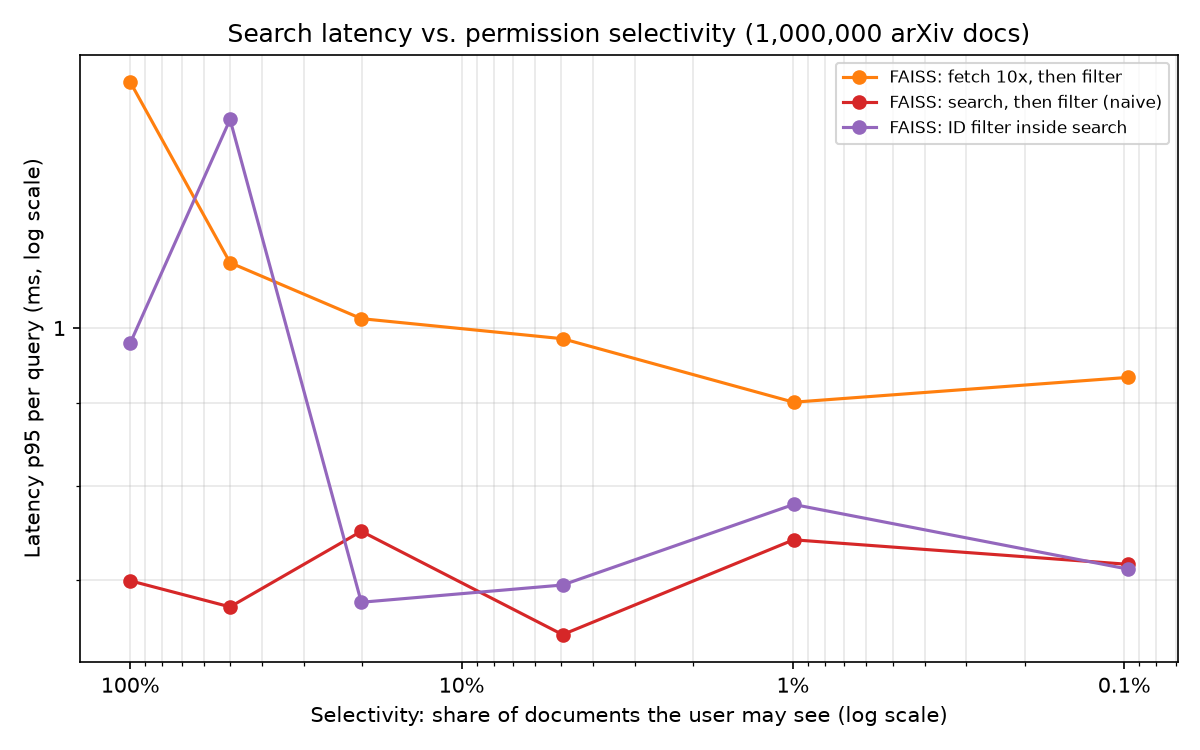

**corpus1m_milvus**

,100.0%,50.0%,20.0%,5.0%,1.0%,0.1%
method,,,,,,
milvus_filter,19.600,6.610,10.220,14.290,8.750,5.090
milvus_partition,8.410,4.620,5.080,4.560,4.490,4.120


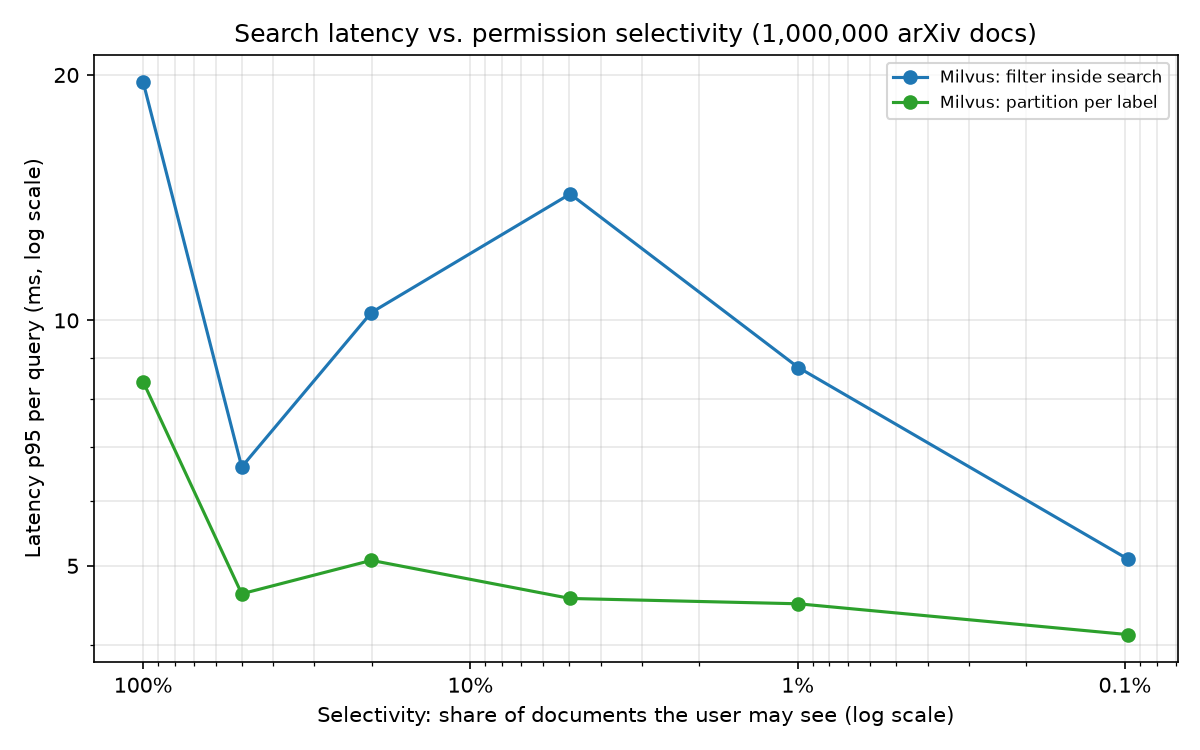

**demo100k**

,100.0%,50.0%,20.0%,5.0%,1.0%,0.1%
method,,,,,,
milvus_filter,5.160,5.990,6.170,5.970,5.240,5.260
milvus_partition,6.210,3.980,4.130,4.200,4.110,3.370
faiss_prefilter,0.480,0.570,0.390,0.450,0.380,0.420
faiss_post_10x,0.670,0.650,0.670,0.590,0.680,0.720
faiss_postfilter,0.380,0.420,0.370,0.350,0.420,0.420


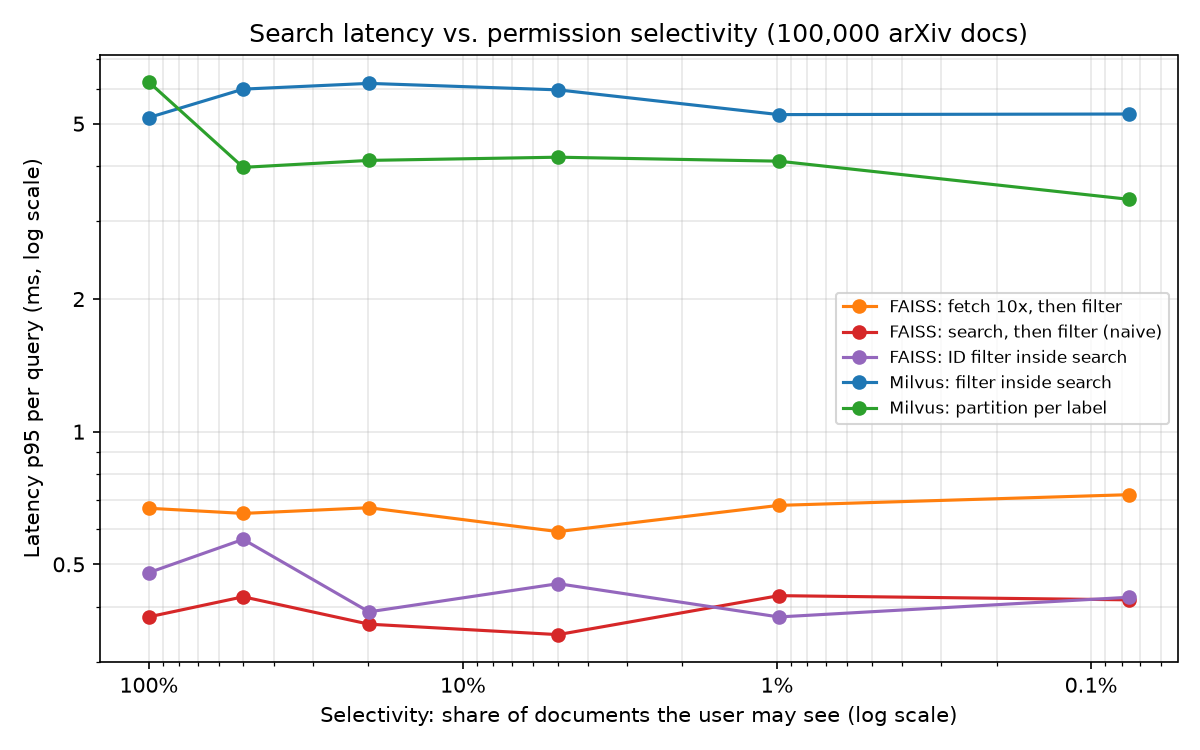

In [4]:
for tag, df in benches.items():
    display(Markdown(f"**{tag}**"))
    t = df.pivot_table(index="method", columns="target", values="latency_p95_ms").reindex([m for m in ORDER if m in set(df.method)])
    t = t[sorted(t.columns, reverse=True)]
    t.columns = [f"{v:.1%}" for v in t.columns]
    display(t.round(2))
    p = f"{R}/latency_vs_selectivity_{tag}.png"
    if os.path.exists(p):
        display(Image(p, width=700))

## 3. Leakage test suite

Every user role runs many queries through both Milvus methods; the test fails if **any** returned
document carries a label that role is not allowed to see (checked on the raw Milvus output, before the
second safety check). Also tests unknown users, filter-injection strings and the HTTP API.

In [5]:
tables = {}
for p in sorted(glob.glob(f"{R}/leak_tests_junit*.xml")):
    root = ET.parse(p).getroot()
    suite = root if root.tag == "testsuite" else root.find("testsuite")
    name = "1M index" if p.endswith("_1m.xml") else "100k index"
    print(name, {k: suite.get(k) for k in ("tests", "failures", "errors", "skipped", "time")})
    tables[name] = pd.DataFrame([{"test": tc.get("name"), "seconds": float(tc.get("time")),
                                  "result": "FAIL" if (tc.find("failure") is not None or tc.find("error") is not None) else "pass"}
                                 for tc in suite.iter("testcase")])
pd.concat(tables, names=["index", "#"])

100k index {'tests': '38', 'failures': '0', 'errors': '0', 'skipped': '0', 'time': '24.401'}
1M index {'tests': '38', 'failures': '0', 'errors': '0', 'skipped': '0', 'time': '31.507'}


test  seconds  \
index      #                                                                
100k index 0   test_no_result_outside_role[ananya.intern-filter]    1.228   
           1   test_no_result_outside_role[ananya.intern-part...    0.799   
           2        test_no_result_outside_role[rahul.cs-filter]    1.101   
           3     test_no_result_outside_role[rahul.cs-partition]    0.848   
           4     test_no_result_outside_role[meera.csmgr-filter]    0.845   
...                                                          ...      ...   
1M index   33               test_filter_injection_is_rejected[*]    0.000   
           34               test_filter_injection_is_rejected[%]    0.000   
           35  test_filter_injection_is_rejected[public OR TRUE]    0.000   
           36                                  test_k_is_clamped    0.013   
           37                           test_api_identity_checks    1.399   

              result  
index      #          
100k index 0    pass  
           1    pass  
           2    pass  
           3    pass  
           4    pass  
...              ...  
1M index   33   pass  
           34   pass  
           35   pass  
           36   pass  
           37   pass  

[76 rows x 3 columns]

### Mutation check

The same suite run with the permission filter **deliberately disabled** (`PAVS_MUTATION=no_filter`,
test code only). Tests on the filter method must fail here; that shows the suite really detects leaks.
Partition-method tests still pass because that mechanism was not broken.

In [6]:
p = f"{R}/mutation_check_junit.xml"
if os.path.exists(p):
    root = ET.parse(p).getroot()
    suite = root if root.tag == "testsuite" else root.find("testsuite")
    print({k: suite.get(k) for k in ("tests", "failures", "errors")})
    m = pd.DataFrame([{"test": tc.get("name"),
                       "result": "FAIL (expected)" if (tc.find("failure") is not None or tc.find("error") is not None) else "pass"}
                      for tc in suite.iter("testcase")])
    display(m[m.result != "pass"])
else:
    print("mutation check not run yet")

{'tests': '38', 'failures': '16', 'errors': '0'}


,test,result
0,test_no_result_outside_role[ananya.intern-filter],FAIL (expected)
2,test_no_result_outside_role[rahul.cs-filter],FAIL (expected)
4,test_no_result_outside_role[meera.csmgr-filter],FAIL (expected)
6,test_no_result_outside_role[kiran.math-filter],FAIL (expected)
8,test_no_result_outside_role[farah.physics-filter],FAIL (expected)
10,test_no_result_outside_role[vikram.phymgr-filter],FAIL (expected)
12,test_no_result_outside_role[sana.analyst-filter],FAIL (expected)
14,test_no_result_outside_role[deepa.hr-filter],FAIL (expected)
16,test_no_result_outside_role[arjun.board-filter],FAIL (expected)
20,test_targeted_restricted_document[filter],FAIL (expected)


## 4. Revocation leak window

A public document is relabelled to `hr-restricted` by a Kafka event. We measure how long the intern can
still find it. Three versions of the stream job: *default* (one micro-batch does Milvus + Iceberg, Spark's
200 shuffle partitions), *tuned* (4 shuffle partitions) and *split* (separate fast path Kafka -> Milvus
every 0.2 s, slow path Kafka -> Iceberg every 1 s).

In [7]:
rev = []
for p in sorted(glob.glob(f"{R}/revocation_*.csv")):
    if "breakdown" in p:
        continue
    d = pd.read_csv(p); d["run"] = os.path.basename(p)[11:-4]; rev.append(d)
rev = pd.concat(rev)
summary = rev.groupby(["run", "consistency"]).agg(trials=("leak_window_s", "size"),
                                                   p50_s=("leak_window_s", "median"),
                                                   p95_s=("leak_window_s", lambda x: x.quantile(0.95)),
                                                   max_s=("leak_window_s", "max"),
                                                   timeouts=("timed_out", "sum"),
                                                   search_ms=("search_ms_median", "median"))
summary

trials  p50_s  p95_s  max_s  timeouts  search_ms
run            consistency                                                  
demo100k       Bounded          20  4.916  6.119  6.181         0      6.083
               Eventually       20  4.799  5.583  5.609         0      6.173
               Strong           20  5.540  7.024 11.508         0      6.873
demo100k_split Bounded          20  1.026  1.374  1.424         0      6.151
               Eventually       20  1.021  1.207  1.360         0      6.103
               Strong           20  1.050  1.490  1.982         0      6.825
demo100k_tuned Bounded          20  3.084  3.627  3.824         0      6.056
               Eventually       20  3.176  3.576  3.797         0      5.946
               Strong           20  3.724  4.255  8.464         0      6.871

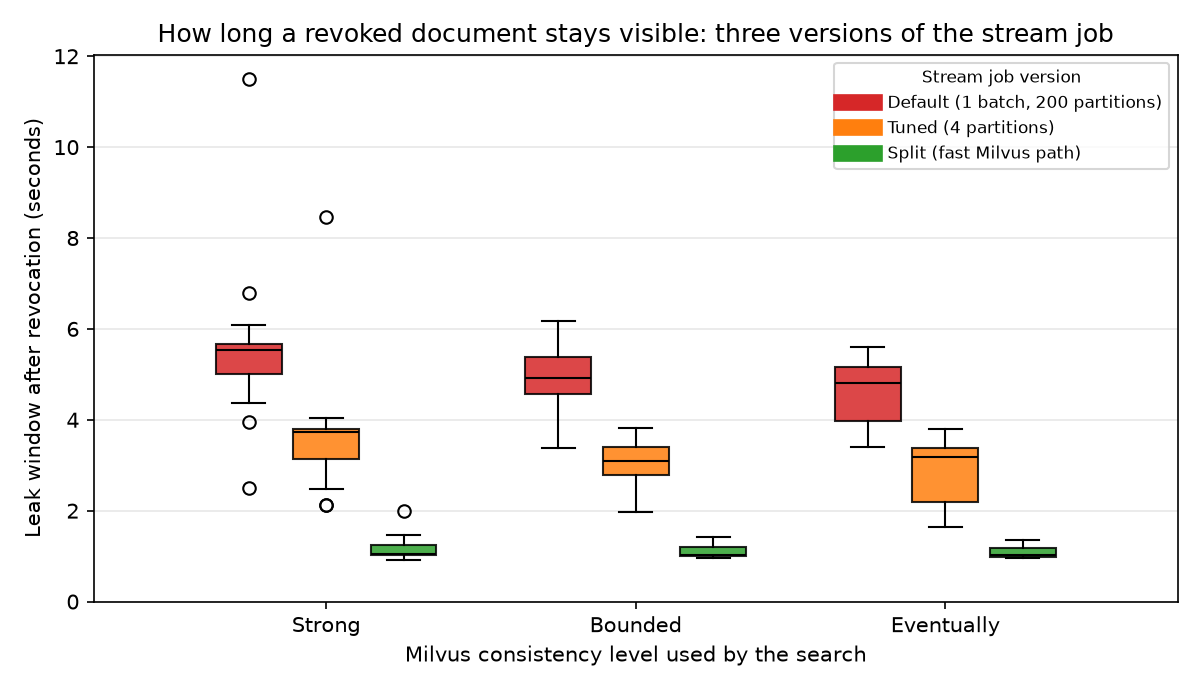

`revocation_window_demo100k.png`

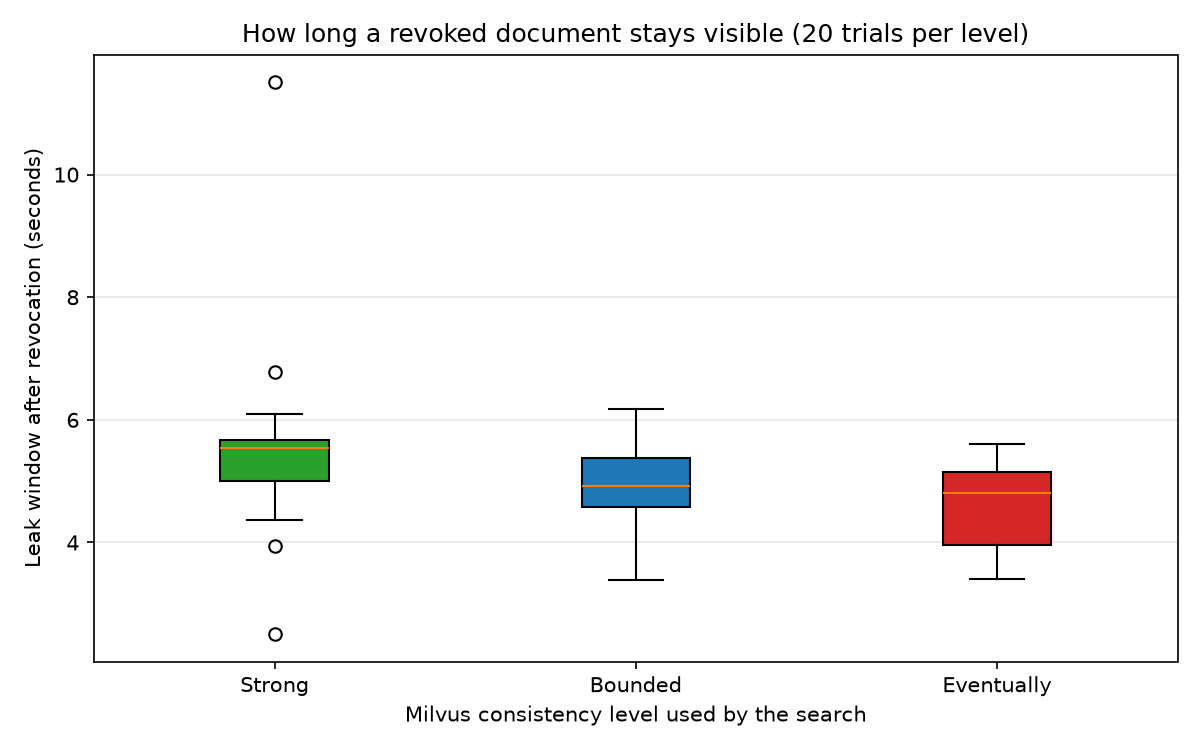

`revocation_window_demo100k_split.png`

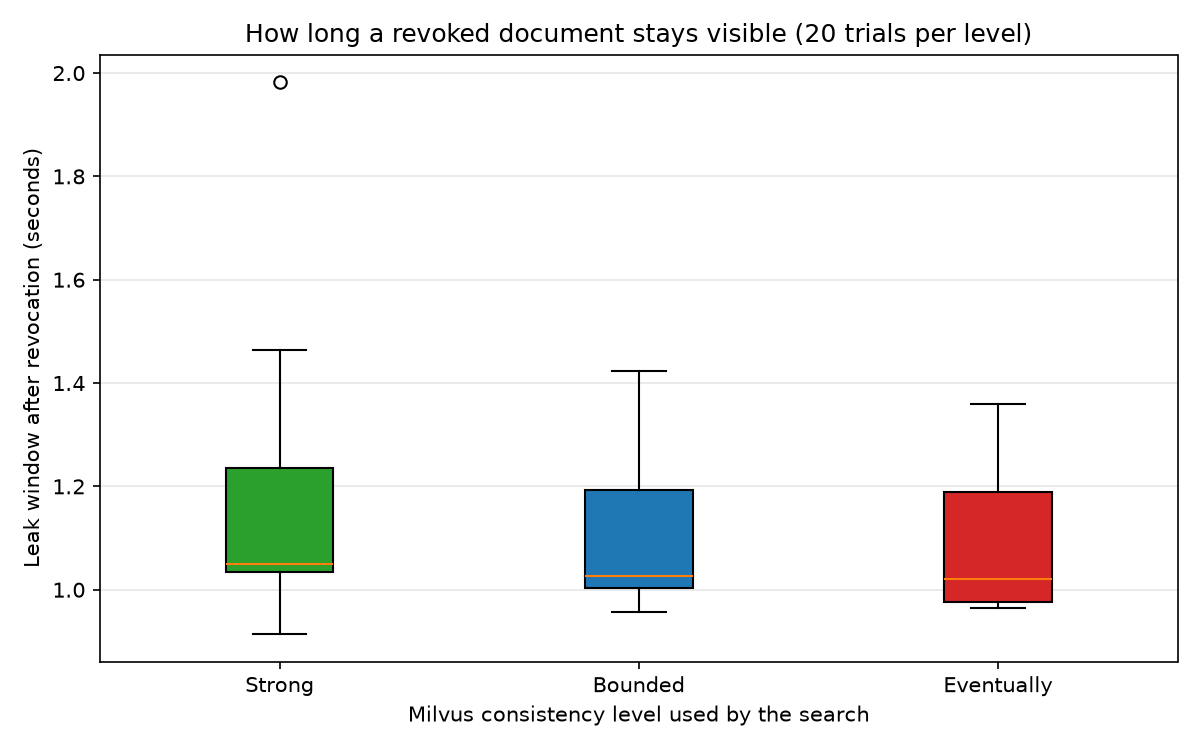

`revocation_window_demo100k_tuned.png`

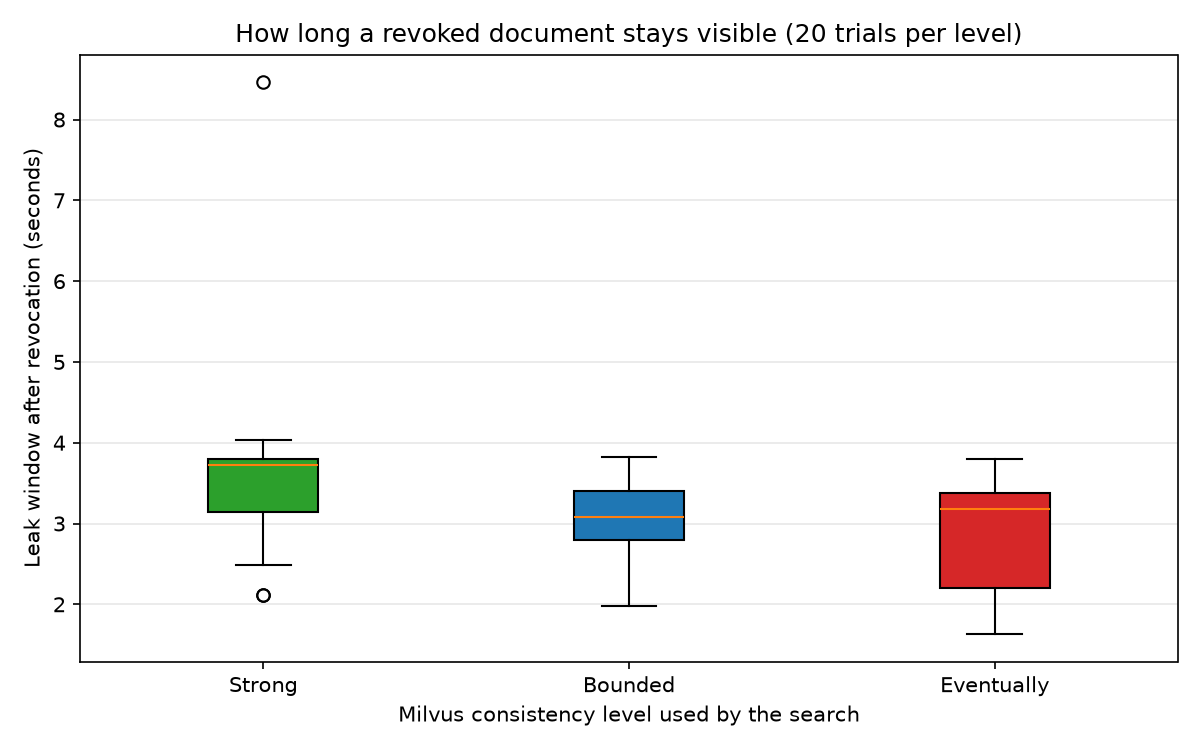

**revocation_breakdown_demo100k.csv**: milliseconds from the Kafka event to Milvus / to Iceberg (quantiles)

,to_milvus_ms,to_lake_ms
0.500,4950.000,8502.000
0.950,6080.000,10153.000
0.990,8700.000,14016.000


**revocation_breakdown_demo100k_split.csv**: milliseconds from the Kafka event to Milvus / to Iceberg (quantiles)

,to_milvus_ms,to_lake_ms
0.500,978.000,7014.000
0.950,1430.000,10265.000
0.990,1646.000,12778.000


**revocation_breakdown_demo100k_tuned.csv**: milliseconds from the Kafka event to Milvus / to Iceberg (quantiles)

,to_milvus_ms,to_lake_ms
0.500,3110.000,4688.000
0.950,3875.000,5957.000
0.990,5815.000,9814.000


In [8]:
p = f"{R}/revocation_comparison.png"
if os.path.exists(p):
    display(Image(p, width=700))
for p in sorted(glob.glob(f"{R}/revocation_window_*.png")):
    display(Markdown(f"`{os.path.basename(p)}`")); display(Image(p, width=600))
for p in sorted(glob.glob(f"{R}/revocation_breakdown_*.csv")):
    display(Markdown(f"**{os.path.basename(p)}**: milliseconds from the Kafka event to Milvus / to Iceberg (quantiles)"))
    display(pd.read_csv(p, index_col=0))